In [2]:
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

files = sorted(glob.glob("CRMLSSold*.csv"))
print(len(files), "files")
raw_data = pd.concat([pd.read_csv(f, low_memory=False) for f in files], ignore_index=True)
print("All rows:", len(raw_data))

15 files
All rows: 324496


In [4]:
df = raw_data[(raw_data["PropertyType"] == "Residential") & (raw_data["PropertySubType"] == "SingleFamilyResidence")]
print("Single-family rows:", len(df))
print("Unique ListingKeys:", df["ListingKey"].nunique())

df = df.drop_duplicates(subset="ListingKey")
print("After removing duplicates:", len(df))

Single-family rows: 162567
Unique ListingKeys: 162454
After removing duplicates: 162454


In [5]:
cols = ["ClosePrice", "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet"]
df[cols].describe()

,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet
count,1.624540e+05,162367.000000,162454.000000,162435.000000,1.596230e+05
mean,1.330773e+06,2045.131788,3.488391,2.630357,3.589873e+05
std,7.601264e+06,1039.033988,0.971444,1.136049,1.773102e+07
min,0.000000e+00,0.000000,0.000000,0.000000,0.000000e+00
25%,6.250000e+05,1384.000000,3.000000,2.000000,5.663000e+03
50%,8.900000e+05,1816.000000,3.000000,2.000000,7.280000e+03
75%,1.423792e+06,2437.000000,4.000000,3.000000,1.045400e+04
max,9.895000e+08,56500.000000,45.000000,45.000000,2.087221e+09


In [6]:
df[cols].isna().mean() 

ClosePrice               0.000000
LivingArea               0.000536
BedroomsTotal            0.000000
BathroomsTotalInteger    0.000117
LotSizeSquareFeet        0.017426
dtype: float64

Median price: 890000.0
Skew: 102.13


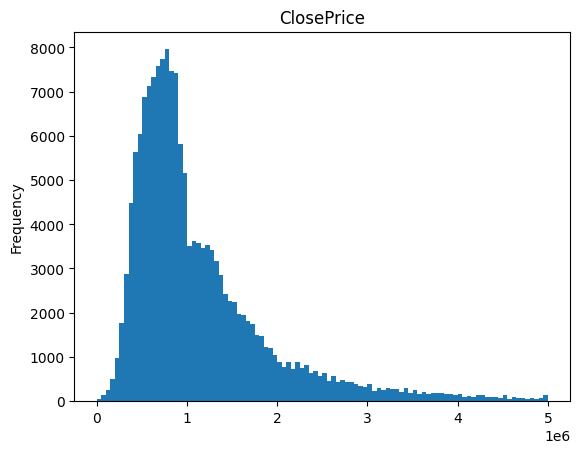

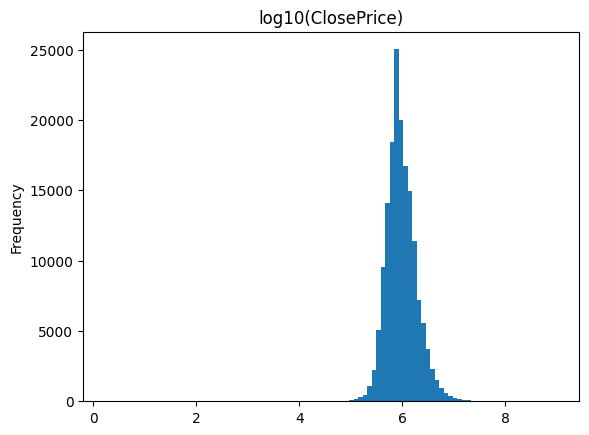

In [7]:
print("Median price:", df["ClosePrice"].median())
print("Skew:", df["ClosePrice"].skew().round(2))

df["ClosePrice"].plot.hist(bins=100, range=(0, 5_000_000), title="ClosePrice")
plt.show()
np.log10(df["ClosePrice"][df["ClosePrice"] > 0]).plot.hist(bins=100, title="log10(ClosePrice)")
plt.show()

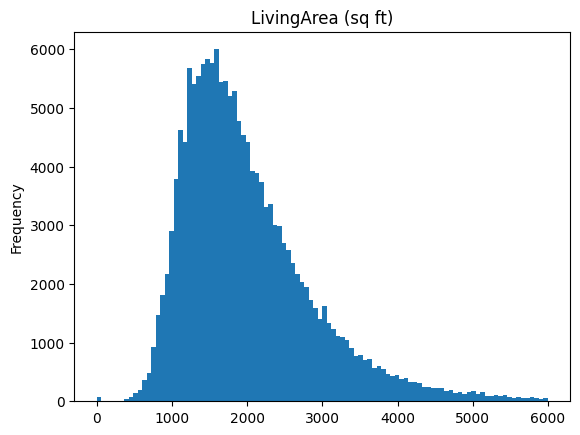

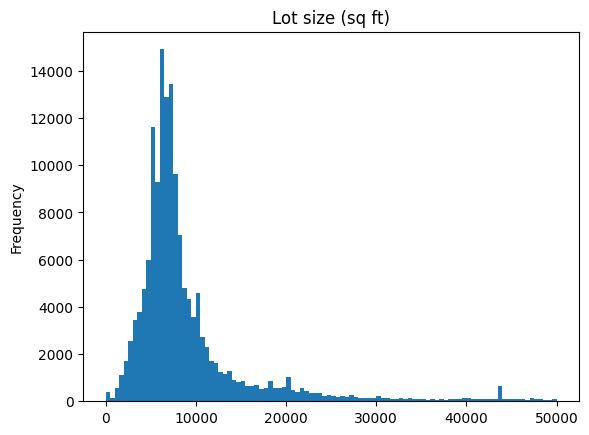

In [8]:
df["LivingArea"].plot.hist(bins=100, range=(0, 6000), title="LivingArea (sq ft)")
plt.show()
df["LotSizeSquareFeet"].plot.hist(bins=100, range=(0, 50_000), title="Lot size (sq ft)")
plt.show()

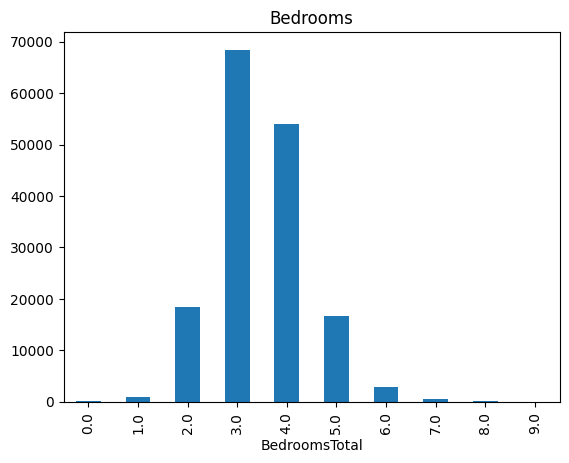

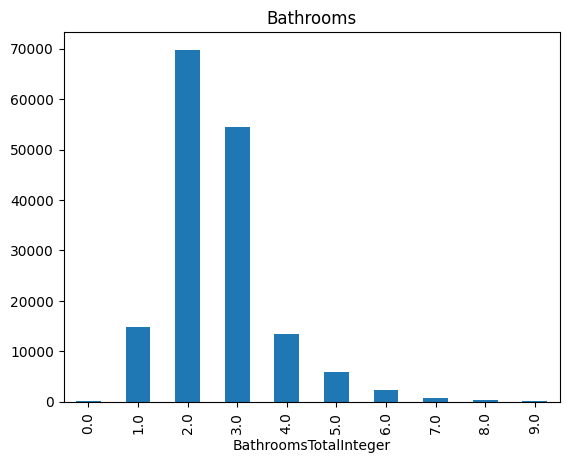

BedroomsTotal
0.0     600000.0
1.0     423500.0
2.0     645000.0
3.0     815000.0
4.0    1035000.0
5.0    1388000.0
6.0    1821250.0
7.0    2300000.0
8.0    1835000.0
9.0    2050000.0
Name: ClosePrice, dtype: float64

In [9]:
df["BedroomsTotal"].value_counts().sort_index().head(10).plot.bar(title="Bedrooms")
plt.show()
df["BathroomsTotalInteger"].value_counts().sort_index().head(10).plot.bar(title="Bathrooms")
plt.show()
df.groupby("BedroomsTotal")["ClosePrice"].median().head(10)

In [10]:
print("Price 0 or missing:", (~(df["ClosePrice"] > 0)).sum())
print("LivingArea 0 or missing:", (~(df["LivingArea"] > 0)).sum())
print("0 bedrooms:", (df["BedroomsTotal"] == 0).sum())
df[cols].corr()["ClosePrice"]

Price 0 or missing: 1
LivingArea 0 or missing: 166
0 bedrooms: 103


ClosePrice               1.000000
LivingArea               0.121338
BedroomsTotal            0.066641
BathroomsTotalInteger    0.107878
LotSizeSquareFeet        0.000667
Name: ClosePrice, dtype: float64

WEEK 3